# TD7: Test of independence of $\chi ^2$ between two qualitative variables

Christelle Gonindard & Matthias Grenié

**Session objective:
Test the existence of dependence between two qualitative variables**.



## Context


This test verifies the absence of a statistical link between two variables X and Y, which are
qualitative variables.
X and Y are said to be independent when there is no statistical link between them,
In other words, knowledge of X does not allow us to make any statement about Y.

The null hypothesis (H0) of this test is that the two variables X and Y are independent.

## Methodology

The data file `TD07_student_smokers.txt` in the `data/` folder contains the responses of 237 statistics students
University of Adelaide to a number of questions. We are interested in
variables:
1. `smoker`: records students' smoking habits, the allowed values in Smoker are `"Heavy"`, `"Regul"` (regularly), `"Occas"` (occasionally) and `"Never"`.
2. `exercise`: records their level of exercise, allowed values are `"Freq"` (frequently), `"Some"` and `"None"`.
3. `gender`: `"Male"` or `"Female"`

These three variables are qualitative. 
It is therefore possible to test the relationship between each of the variables, two by two, using a $\chi ^2$ of independence. 

**For example, we can test whether there is a link between students' smoking habits and their level of exercise.**


## Data presentation

1. Reading the data

In [1]:
# Read data file
smokers = read.table("data/TD07_student_smokers.txt", header = TRUE)

# Display start of data file contents
head(smokers)
summary(smokers)

table(smokers$gender)

,smoker,exercise,gender
,<chr>,<chr>,<chr>
1,Never,Some,Female
2,Regul,None,Male
3,Occas,None,Male
4,Never,None,Male
5,Never,Some,Male
6,Never,Some,Female


    smoker            exercise            gender         
 Length:237         Length:237         Length:237        
 Class :character   Class :character   Class :character  
 Mode  :character   Mode  :character   Mode  :character  


Female   Male 
   119    118 

2. Consider the variables *Smoker* and *Exercise* : 
    - Display the observed numbers
    - Plot them on a graph


Heavy Never Occas Regul 
   11   190    19    17 


Freq None Some 
 115   24   98 

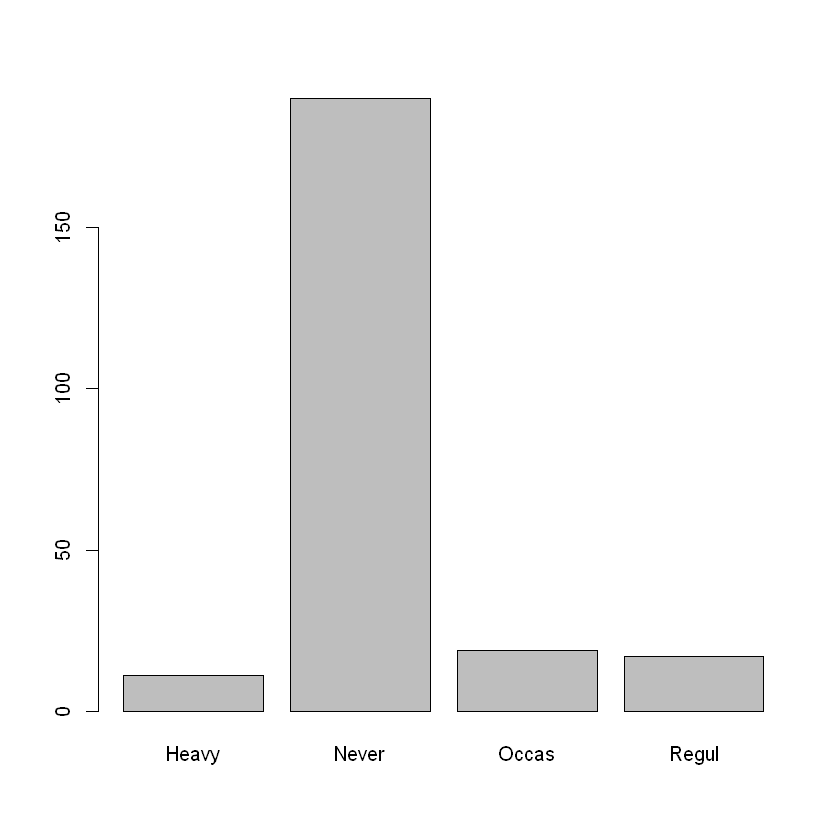

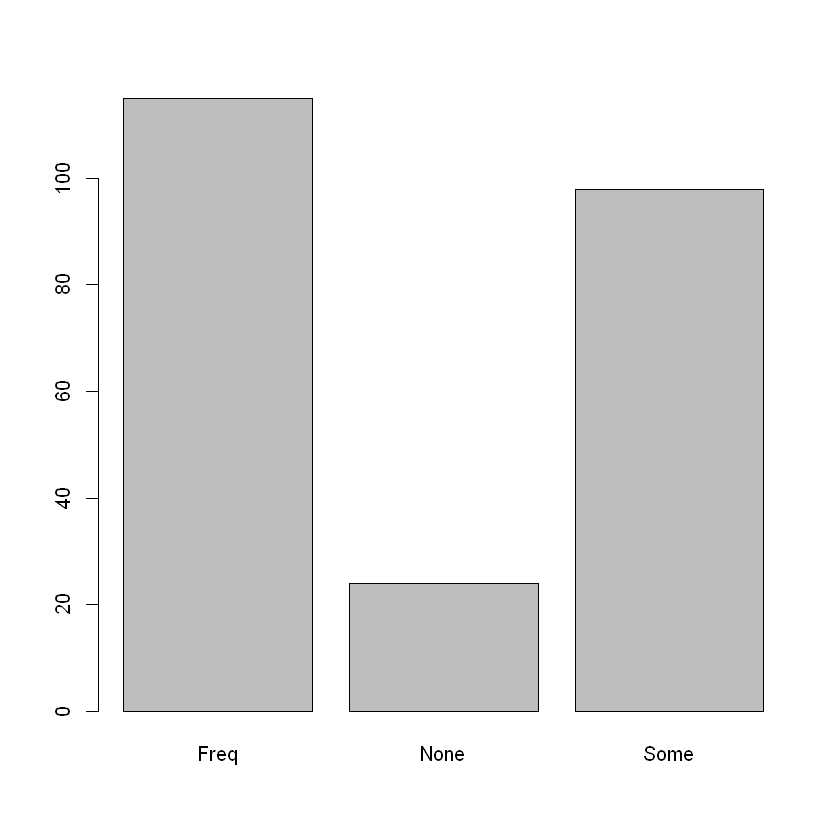

In [2]:
# Observed numbers
table(smokers$smoker)
table(smokers$exercise)

# Graph representing these observed numbers
barplot(table(smokers$smoker))
barplot(table(smokers$exercise))

**Comment**:  
Most students never smoke and exercise at least a bit

## Hypotheses

Specify hypotheses H0 and H1



Because we're performing a chi² test we're testing if there is a link between two variables

H0: There is no link between the smoking habits of students and their exercise frequency

H1: There is a link between the smoking habits of students and their exercice frequency


## Checking application conditions

Theoretical counts under H0 must be greater than 5, not to be confused with observed numbers in the sample.

In [3]:
# Computation of the theoretical counts under H0
chisq.test(smokers$smoker, smokers$exercise)$expected

Warning message in chisq.test(smokers$smoker, smokers$exercise):
"L’approximation du Chi-2 est peut-être incorrecte"


,Freq,None,Some
Heavy,5.337553,1.113924,4.548523
Never,92.194093,19.240506,78.565401
Occas,9.219409,1.924051,7.856540
Regul,8.248945,1.721519,7.029536


**Comment**:  
We see theoretical counts below 5 for 3 cells in the "None" columns and 1 in the "Some" columns.  
We can't proceed to perform the chi-square test. If we want to perform it, we would need to merge the columns "None" and "Some".

That's what we're going to do

In [4]:
# Create new column "exercise2"
smokers$exercise2 = smokers$exercise

# Replace the `None` by `Some`
smokers$exercise2[smokers$exercise2 == "None"] = "Some"

# Check the new values
table(smokers$exercise2)



Freq Some 
 115  122 

Check that the theoretical number of employees associated with this new grouping is greater than 5. 

In [5]:
# Compute the new theoretical counts under H0
chisq.test(smokers$smoker, smokers$exercise2)$expected

,Freq,Some
Heavy,5.337553,5.662447
Never,92.194093,97.805907
Occas,9.219409,9.780591
Regul,8.248945,8.751055


After checking that the theoretical numbers are well above 5, we can perform the $\chi ^2$ test.

## Performing the test

To perform the test you can use the `chisq.test()` function which takes as first argument the table of observed counts.

In [6]:
# Perform the test
chisq.test(smokers$smoker, smokers$exercise2)


	Pearson's Chi-squared test

data:  smokers$smoker and smokers$exercise2
X-squared = 3.3363, df = 3, p-value = 0.3426


**Conclusion**:

We observe p = 0.34 >>> alpha = 0.05, so we can't reject H0, which means there is no link between smoking habits and exercise frequency.

## Application exercise

The data file is `TD07_tobacco.txt` located in the `data/` folder. This is a study of 100 patients in a hospital ward to check the relationship between smoking and lung problems.
To do this, we asked each person:
- their `age`,
- their `sex`,
- their marital `status` (single,
married, etc.),
- smoking habits (number of cigarettes per day), presence of passive smoking
and the presence of lung problems (lung cancer, COPD, etc.).

The `smoker` variable is defined as follows: `FALSE` if they don't smoke cigarettes and
`TRUE` if they smokes at least 1 cigarette a day.

Answer the following questions:

1. Do smokers have significantly more lung problems?

In [11]:
# We need to perform a chi-square test between smoking habits and lung problems
# The hypotheses will be:
# H0: There is no link between smoking habits and lung problems
# H1: The is a link between smoking habits and lung problems

tobacco = read.table("data/TD07_tobacco.txt", header = TRUE)
head(tobacco)
summary(tobacco)

# Check chi-square conditions of application
chisq.test(tobacco$smoker, tobacco$lung_condition)$expected
# => all theoretical counts >= 5 so we can perform the test

chisq.test(tobacco$smoker, tobacco$lung_condition)
# => we observe p = 2.2⋅10⁻⁷ <<< alpha = 0.05, so we reject H0
#    and there is a link between lung conditions and smoking habits
table(tobacco$smoker, tobacco$lung_condition)
# Given the data we can even say there is a strong association between smoking and having lung conditions

,id,age,sex,status,cigarettes_per_day,passive_smoking,lung_condition,smoker
,<int>,<int>,<chr>,<chr>,<int>,<lgl>,<lgl>,<lgl>
1,0,37,man,married,11,FALSE,TRUE,TRUE
2,1,23,man,single,8,FALSE,FALSE,TRUE
3,2,21,man,widowed,0,FALSE,FALSE,FALSE
4,3,55,man,single,0,TRUE,FALSE,FALSE
5,4,61,woman,in_a_relationship,6,FALSE,TRUE,TRUE
6,5,37,man,married,0,FALSE,FALSE,FALSE


       id             age            sex               status         
 Min.   : 0.00   Min.   :20.00   Length:100         Length:100        
 1st Qu.:24.75   1st Qu.:29.75   Class :character   Class :character  
 Median :49.50   Median :41.00   Mode  :character   Mode  :character  
 Mean   :49.50   Mean   :41.38                                        
 3rd Qu.:74.25   3rd Qu.:52.25                                        
 Max.   :99.00   Max.   :64.00                                        
 cigarettes_per_day passive_smoking lung_condition    smoker       
 Min.   : 0.0       Mode :logical   Mode :logical   Mode :logical  
 1st Qu.: 0.0       FALSE:84        FALSE:65        FALSE:51       
 Median : 0.0       TRUE :16        TRUE :35        TRUE :49       
 Mean   : 3.9                                                      
 3rd Qu.: 9.0                                                      
 Max.   :14.0                                                      

,FALSE,TRUE
FALSE,33.15,17.85
TRUE,31.85,17.15



	Pearson's Chi-squared test with Yates' continuity correction

data:  tobacco$smoker and tobacco$lung_condition
X-squared = 26.828, df = 1, p-value = 2.224e-07


       
        FALSE TRUE
  FALSE    46    5
  TRUE     19   30

2. Is there a link between passive smoking and lung problems?